## Confusion Matrices

Visualizations for understanding where predictions are lacking

In [1]:
# 1 — Inventory saved query exports. No old notebook variables are needed.
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

ROOT = Path.home() / "scgpt-cna"
EXTRA_QUERY_DIRS = []  # Optional directories containing query_predictions_mask*.csv.gz.
SEARCH_ROOTS = {
    "Lab": ROOT / "multicase_expression/results",
    "Census": ROOT / "census_expression/results",
    "Aggregation": ROOT / "aggregation_pilot/results",
}
METHODS = ["GEP", "MVC", "gene_mean_plus_offset"]
GROUPS = ["all", "1 UMI", "2–4 UMIs", "5+ UMIs"]
DISPLAY_GROUPS = ["all"]  # Every GROUP is saved; only these are displayed inline.
LABELS = {"GEP": "GEP", "MVC": "MVC", "gene_mean_plus_offset": "Gene mean + offset"}

def read_json(path):
    return json.loads(path.read_text()) if path.is_file() else {}

def inventory_exports():
    parents = {}
    for kind, base in SEARCH_ROOTS.items():
        if base.is_dir():
            for f in base.rglob("query_predictions_mask*.csv.gz"):
                parents[f.parent.resolve()] = kind
    for directory in EXTRA_QUERY_DIRS:
        parents[Path(directory).expanduser().resolve()] = "Custom"
    rows = []
    for directory, kind in sorted(parents.items(), key=lambda item: str(item[0])):
        files = sorted(directory.glob("query_predictions_mask*.csv.gz"))
        if not files:
            continue
        first = pd.read_csv(files[0], nrows=1)
        if first.empty:
            continue
        row = first.iloc[0]
        run = next((p for p in [directory, *directory.parents] if (p/"run_manifest.json").is_file()), directory.parent)
        manifest = read_json(run/"run_manifest.json")
        sid = str(row.get("sample_id", directory.name))
        source_sid = str(row.get("source_sample_id", sid))
        tissue, diagnosis = "not recorded", "not recorded"
        for name in ["sample_manifest.tsv", "cohort_manifest.tsv"]:
            path = run/name
            if path.is_file():
                meta = pd.read_csv(path, sep="\t", dtype=str)
                if "sample_id" in meta:
                    match = meta.loc[meta.sample_id.eq(source_sid)]
                    if len(match) == 1:
                        tissue = match.iloc[0].get("primary_site", tissue)
                        diagnosis = match.iloc[0].get("diagnoses.0.primary_diagnosis", diagnosis)
        if kind == "Census":
            tissue, diagnosis = "Kidney", "Census-annotated proximal-tubule cohort"
        actual = sorted(int(re.search(r"mask(\d+)", f.name).group(1)) for f in files)
        expected = sorted(map(int, manifest.get("mask_seeds", actual)))
        rows.append(dict(source=kind, sample_id=sid, case_id=str(row.get("case_id", "unknown")),
                         tissue=tissue, diagnosis=diagnosis, pool_size=row.get("pool_size", np.nan),
                         mode=manifest.get("mode", "unknown"), run=run.name, n_mask_files=len(files),
                         masks=",".join(map(str, actual)), masks_complete=actual == expected,
                         methods_available=", ".join(m for m in METHODS if m in first),
                         directory=str(directory), run_directory=str(run)))
    return pd.DataFrame(rows)

inventory = inventory_exports()
assert not inventory.empty, "No query exports found. Check ROOT/EXTRA_QUERY_DIRS; summary CSVs alone cannot produce these heat maps."
inventory.index.name = "dataset_id"
with pd.option_context("display.max_columns", None, "display.max_colwidth", 85):
    display(inventory)
print("Choose dataset_id values below. Select one run per specimen/condition; do not select duplicate reruns for comparison.")


,source,sample_id,case_id,tissue,diagnosis,pool_size,mode,run,n_mask_files,masks,masks_complete,methods_available,directory,run_directory
dataset_id,,,,,,,,,,,,,,
0,Aggregation,C3N-00148-01__cluster0__pool01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",1.0,pilot,20261110T180438530299Z_pilot,1,42,True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot/poo...,/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot
1,Aggregation,C3N-00148-01__cluster0__pool05,C3N-00148,Kidney,"Renal cell carcinoma, NOS",5.0,pilot,20261110T180438530299Z_pilot,1,42,True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot/poo...,/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot
2,Aggregation,C3N-00148-01__cluster0__pool10,C3N-00148,Kidney,"Renal cell carcinoma, NOS",10.0,pilot,20261110T180438530299Z_pilot,1,42,True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot/poo...,/home/akash1/scgpt-cna/aggregation_pilot/results/20261110T180438530299Z_pilot
3,Census,CENSUS_PROXIMAL_TUBULE_256,not_applicable,Kidney,Census-annotated proximal-tubule cohort,NaN,full,20261110T170724523313Z_full,4,"42,43,44,45",True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full/CENS...,/home/akash1/scgpt-cna/census_expression/results/20261110T170724523313Z_full
4,Lab,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",NaN,pilot,20261105T165511541582Z_pilot,1,42,True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/multicase_expression/results/20261105T165511541582Z_pilot/...,/home/akash1/scgpt-cna/multicase_expression/results/20261105T165511541582Z_pilot
5,Lab,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",NaN,full,20261105T170138623982Z_full,4,"42,43,44,45",True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C...,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full
6,Lab,C3L-01287-01,C3L-01287,Kidney,"Renal cell carcinoma, NOS",NaN,full,20261105T170138623982Z_full,4,"42,43,44,45",True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C...,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full
7,Lab,C3N-00148-01,C3N-00148,Kidney,"Renal cell carcinoma, NOS",NaN,full,20261105T170138623982Z_full,4,"42,43,44,45",True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full/C...,/home/akash1/scgpt-cna/multicase_expression/results/20261105T170138623982Z_full
8,Lab,C3L-00359-01,C3L-00359,Kidney,"Renal cell carcinoma, NOS",NaN,full,20261105T212842316783Z_full,4,"42,43,44,45",True,"GEP, MVC, gene_mean_plus_offset",/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full/C...,/home/akash1/scgpt-cna/multicase_expression/results/20261105T212842316783Z_full


Choose dataset_id values below. Select one run per specimen/condition; do not select duplicate reruns for comparison.


In [3]:
# 2 — Choose inventory rows explicitly. You can process several in one run.
SELECT_IDS = [3, 17, 18, 19, 20, 21, 22]  # e.g. [0, 3, 4]; replace after looking at cell 1.
assert SELECT_IDS, "Set SELECT_IDS to dataset_id values from the inventory above, then rerun this cell."
assert len(SELECT_IDS) == len(set(SELECT_IDS))
assert set(SELECT_IDS).issubset(inventory.index)
selected = inventory.loc[SELECT_IDS].copy()
assert selected.directory.is_unique
if not selected.masks_complete.all():
    print("WARNING: some runs lack their expected mask files. These plots include available files only.")
OUT = ROOT / "expression_heatmaps" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT.mkdir(parents=True, exist_ok=False)
selected.to_csv(OUT / "selected_datasets.csv", index_label="dataset_id")
print("Saving figures and numerical tables to:", OUT)
display(selected[["source", "sample_id", "tissue", "pool_size", "mode", "run", "masks"]])


Saving figures and numerical tables to: /home/akash1/scgpt-cna/expression_heatmaps/20261112T145609922822Z


,source,sample_id,tissue,pool_size,mode,run,masks
dataset_id,,,,,,,
3,Census,CENSUS_PROXIMAL_TUBULE_256,Kidney,NaN,full,20261110T170724523313Z_full,"42,43,44,45"
17,Lab,C3L-00359-01,Kidney,NaN,full,20261107T201746942721Z_full,"42,43,44,45"
18,Lab,C3L-01287-01,Kidney,NaN,full,20261107T201746942721Z_full,"42,43,44,45"
19,Lab,C3N-00148-01,Kidney,NaN,full,20261107T201746942721Z_full,"42,43,44,45"
20,Lab,C3L-03405-01,Brain,NaN,full,20261107T202830268340Z_full,"42,43,44,45"
21,Lab,C3N-01798-01,Brain,NaN,full,20261107T202830268340Z_full,"42,43,44,45"
22,Lab,C3N-01816-01,Brain,NaN,full,20261107T202830268340Z_full,"42,43,44,45"


In [4]:
# 3 — Validate query-level files and construct matrices/continuous diagnostics.
BINS = np.arange(1, 51)

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

def load_queries(directory):
    frames, provenance = [], []
    for path in sorted(Path(directory).glob("query_predictions_mask*.csv.gz")):
        df = pd.read_csv(path)
        required = ["sample_id", "cell_id", "mask_seed", "gene_token", "original_umi", "target_bin", *METHODS]
        missing = set(required) - set(df)
        assert not missing, f"{path.name}: missing {sorted(missing)}. Need the per-query exports from the revised pipeline."
        assert not df.empty
        file_seed = int(re.search(r"mask(\d+)", path.name).group(1))
        assert df.mask_seed.eq(file_seed).all(), f"Mask identity mismatch: {path}"
        frames.append(df[required + (["pooled_umi"] if "pooled_umi" in df else [])])
        provenance.append(dict(path=str(path), sha256=sha256(path), n_rows=len(df)))
    assert frames, "No query files in selected directory."
    q = pd.concat(frames, ignore_index=True)
    assert q.sample_id.nunique() == 1, "Mixed specimens/conditions in one query directory."
    assert q.cell_id.notna().all()
    assert not q.duplicated(["sample_id", "cell_id", "mask_seed", "gene_token"]).any(), "Duplicate query events detected."
    numeric = q[["target_bin", "original_umi", *METHODS]].to_numpy(dtype=float)
    assert np.isfinite(numeric).all(), "Nonfinite targets or predictions."
    target = q.target_bin.to_numpy(dtype=float)
    assert np.all(target == np.rint(target)) and np.all((target >= 1) & (target <= 50))
    assert (q.original_umi >= 1).all() and np.all(q.original_umi == np.rint(q.original_umi))
    if "pooled_umi" in q:
        np.testing.assert_array_equal(q.original_umi, q.pooled_umi)
    return q, provenance

def group_mask(q, group):
    return {"all": np.ones(len(q), dtype=bool), "1 UMI": q.original_umi.eq(1).to_numpy(),
            "2–4 UMIs": q.original_umi.between(2,4).to_numpy(), "5+ UMIs": q.original_umi.ge(5).to_numpy()}[group]

def rounded_bins(pred):
    return np.clip(np.floor(np.asarray(pred) + .5), 1, 50).astype(int)

def calculate(q, group):
    part = q.loc[group_mask(q, group)].copy()
    if part.empty:
        return None
    matrices, normalized, residuals, metrics = {}, {}, {}, []
    y = part.target_bin.to_numpy(dtype=int)
    unique_pairs = part[["cell_id", "gene_token"]].drop_duplicates().shape[0]
    for method in METHODS:
        p = part[method].to_numpy(dtype=float)
        b = rounded_bins(p)
        cm = np.bincount((y-1)*50 + (b-1), minlength=2500).reshape(50,50)
        support = cm.sum(axis=1)
        pct = np.full((50,50), np.nan)
        np.divide(100*cm, support[:,None], out=pct, where=support[:,None] > 0)
        matrices[method], normalized[method] = cm, pct
        error = p-y
        work = part[["cell_id", "mask_seed", "target_bin"]].copy()
        work["error"], work["sq_error"], work["abs_error"] = error, error**2, abs(error)
        balanced = work.groupby(["cell_id", "mask_seed"])[["sq_error", "abs_error"]].mean().groupby("cell_id").mean()
        curve = work.groupby("target_bin").agg(n_queries=("error", "size"), mean_residual=("error", "mean"),
            median_residual=("error", "median"), mean_absolute_error=("abs_error", "mean"),
            residual_p10=("error", lambda x: x.quantile(.1)), residual_p90=("error", lambda x: x.quantile(.9)))
        residuals[method] = curve
        metrics.append(dict(count_group=group, method=method, n_cells=part.cell_id.nunique(),
            n_query_events=len(part), unique_cell_gene_pairs=unique_pairs,
            n_masks=part.mask_seed.nunique(), query_weighted_MSE=float(np.mean(error**2)),
            query_weighted_MAE=float(np.mean(abs(error))), cell_balanced_MSE=balanced.sq_error.mean(),
            cell_balanced_MAE=balanced.abs_error.mean(), query_weighted_signed_error=error.mean(),
            rounded_exact_pct=100*np.mean(b==y), rounded_within1_pct=100*np.mean(abs(b-y)<=1),
            rounded_under_pct=100*np.mean(b<y), rounded_over_pct=100*np.mean(b>y),
            raw_prediction_below1_pct=100*np.mean(p<1), raw_prediction_above50_pct=100*np.mean(p>50)))
    return dict(counts=matrices, percent=normalized, residuals=residuals,
                metrics=pd.DataFrame(metrics), support=support, n_queries=len(part))

analyses, metric_tables, provenance_all = {}, [], []
for dataset_id, record in selected.iterrows():
    q, provenance = load_queries(record.directory)
    assert q.sample_id.eq(record.sample_id).all()
    destination = OUT / f"dataset_{dataset_id:03d}"
    destination.mkdir()
    unit = "aggregates" if record.source == "Aggregation" else "cells"
    title = f"{record.sample_id} | {record.tissue} | {record.diagnosis}"
    if record.source == "Aggregation":
        title += f" | pool size {int(record.pool_size)}"
    title += f"\n{q.cell_id.nunique()} {unit}; {q.mask_seed.nunique()} masks; {record['mode']}"
    by_group = {}
    for group in GROUPS:
        result = calculate(q, group)
        if result is None:
            print(f"Skipping empty group: {record.sample_id}, {group}")
            continue
        slug = {"all":"all", "1 UMI":"1_UMI", "2–4 UMIs":"2_to_4_UMIs", "5+ UMIs":"5plus_UMIs"}[group]
        for method in METHODS:
            pd.DataFrame(result["counts"][method], index=BINS, columns=BINS).rename_axis("true_bin").to_csv(destination/f"{slug}_{method}_counts.csv")
            pd.DataFrame(result["percent"][method], index=BINS, columns=BINS).rename_axis("true_bin").to_csv(destination/f"{slug}_{method}_row_percent.csv")
            result["residuals"][method].to_csv(destination/f"{slug}_{method}_continuous_residuals.csv")
        by_group[group] = (slug, result)
        metric_tables.append(result["metrics"].assign(dataset_id=dataset_id, sample_id=record.sample_id, source=record.source))
    analyses[dataset_id] = dict(title=title, groups=by_group, destination=destination)
    provenance_all.append(dict(dataset_id=int(dataset_id), files=provenance))
    print(f"Loaded {record.sample_id}: {len(q):,} query events, {q.cell_id.nunique()} {unit}.")
    del q
metrics = pd.concat(metric_tables, ignore_index=True)
metrics.to_csv(OUT/"prediction_error_metrics.csv", index=False)
(OUT/"plot_manifest.json").write_text(json.dumps(dict(sources=provenance_all,
    rounding="floor(prediction+0.5), then clip 1..50 for matrices only", methods=METHODS,
    groups=GROUPS, matrix_weighting="query events, including repeated pairs across masks",
    continuous_metrics="raw unclipped predictions", bins="per-profile quantile ranks, not common UMI intervals"), indent=2))
display(metrics[["sample_id", "count_group", "method", "n_cells", "n_query_events", "cell_balanced_MSE",
                 "query_weighted_signed_error", "rounded_exact_pct", "raw_prediction_below1_pct", "raw_prediction_above50_pct"]].round(3))


Loaded CENSUS_PROXIMAL_TUBULE_256: 102,180 query events, 128 cells.
Loaded C3L-00359-01: 137,380 query events, 128 cells.
Loaded C3L-01287-01: 140,792 query events, 128 cells.
Loaded C3N-00148-01: 143,420 query events, 128 cells.
Loaded C3L-03405-01: 125,892 query events, 128 cells.
Loaded C3N-01798-01: 152,428 query events, 128 cells.
Loaded C3N-01816-01: 151,444 query events, 128 cells.


,sample_id,count_group,method,n_cells,n_query_events,cell_balanced_MSE,query_weighted_signed_error,rounded_exact_pct,raw_prediction_below1_pct,raw_prediction_above50_pct
0,CENSUS_PROXIMAL_TUBULE_256,all,GEP,128,102180,10.622,-0.012,23.149,0.0,0.080
1,CENSUS_PROXIMAL_TUBULE_256,all,MVC,128,102180,10.970,-0.139,22.447,0.0,0.250
2,CENSUS_PROXIMAL_TUBULE_256,all,gene_mean_plus_offset,128,102180,18.994,0.003,8.925,0.0,0.669
3,CENSUS_PROXIMAL_TUBULE_256,1 UMI,GEP,128,67895,6.209,1.717,29.811,0.0,0.000
4,CENSUS_PROXIMAL_TUBULE_256,1 UMI,MVC,128,67895,6.474,1.632,30.004,0.0,0.000
...,...,...,...,...,...,...,...,...,...,...
79,C3N-01816-01,2–4 UMIs,MVC,128,41882,36.003,-5.216,2.526,0.0,0.002
80,C3N-01816-01,2–4 UMIs,gene_mean_plus_offset,128,41882,33.721,-4.606,4.646,0.0,0.544
81,C3N-01816-01,5+ UMIs,GEP,128,9635,49.966,-6.787,4.286,0.0,0.654
82,C3N-01816-01,5+ UMIs,MVC,128,9635,53.801,-7.149,2.148,0.0,0.986


Cell: C3N-01798-01:AACAACCCAACGTTAC-1
Queried genes: 299
Occupied TRUE bins among queried genes: [37, 45, 47, 48, 49]


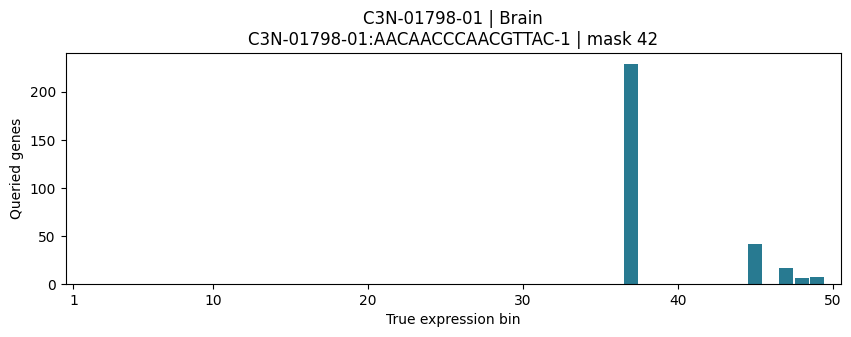

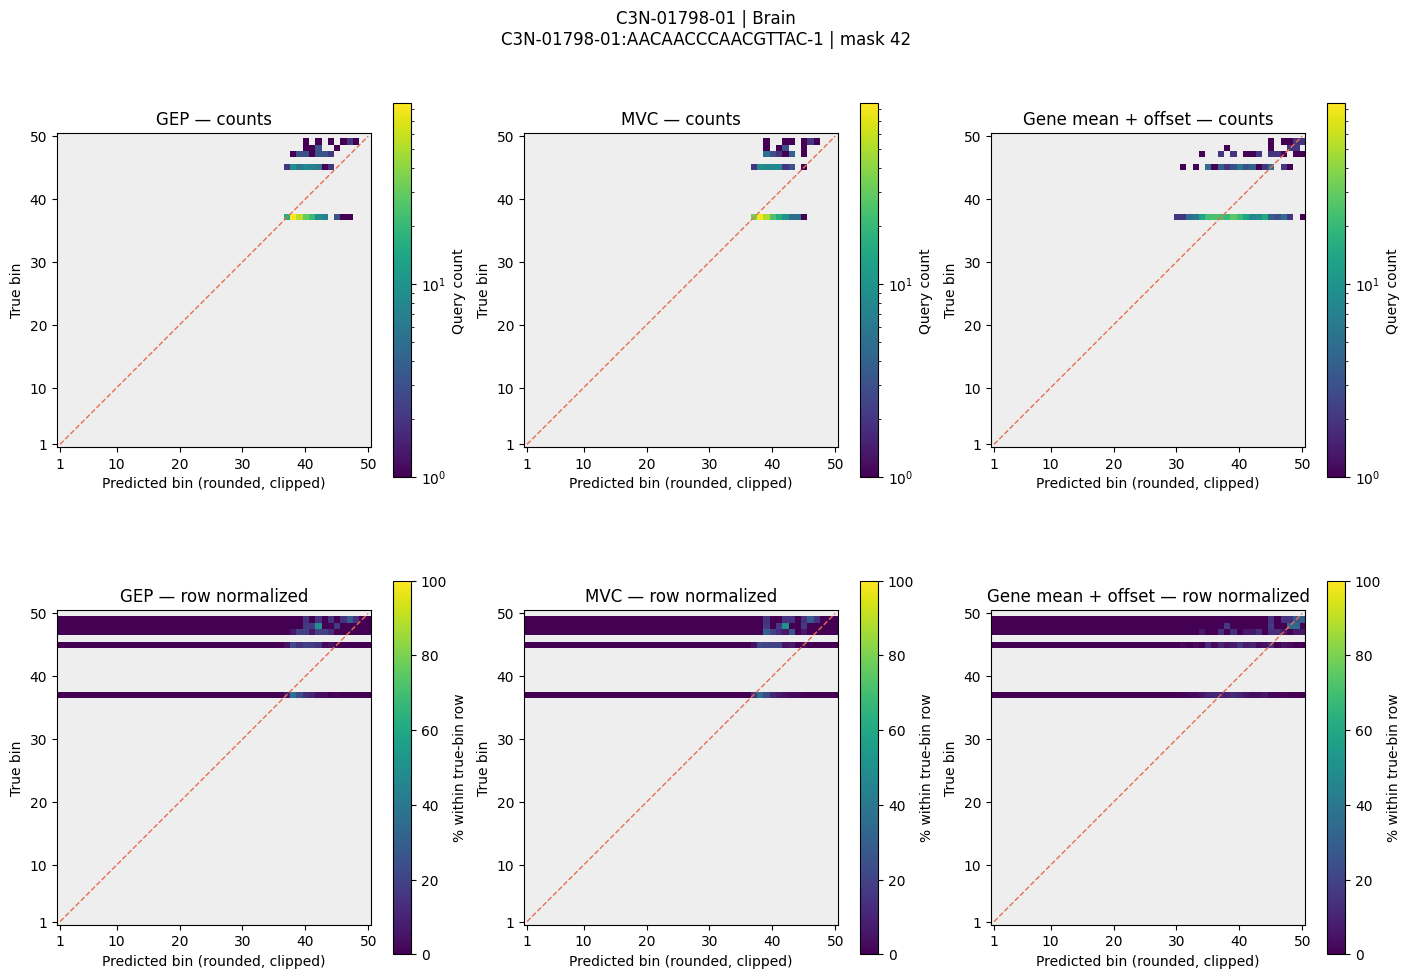

,method,query_weighted_MSE,query_weighted_MAE,query_weighted_signed_error,rounded_exact_pct
0,GEP,12.996,2.878,0.447,5.351
1,MVC,12.731,2.754,0.212,11.706
2,gene_mean_plus_offset,20.843,3.505,0.242,11.037


In [6]:
# Single-cell inspection — saved predictions only, no inference.
DATASET_ID = 21
CELL_POSITION = 0       # Try 1, 2, 3, ... for other evaluated cells.
MASK_SEED = 42

record = inventory.loc[DATASET_ID]
single_queries, _ = load_queries(record["directory"])

available_cells = sorted(single_queries["cell_id"].unique())
assert 0 <= CELL_POSITION < len(available_cells)
chosen_cell = available_cells[CELL_POSITION]

single_queries = single_queries.loc[
    single_queries["cell_id"].eq(chosen_cell)
    & single_queries["mask_seed"].eq(MASK_SEED)
].copy()
assert not single_queries.empty, "No saved queries for this cell/mask."

result = calculate(single_queries, "all")
title = (
    f"{record['sample_id']} | {record['tissue']}\n"
    f"{chosen_cell} | mask {MASK_SEED}"
)

print("Cell:", chosen_cell)
print("Queried genes:", len(single_queries))
print("Occupied TRUE bins among queried genes:",
      sorted(single_queries["target_bin"].astype(int).unique()))

# First: show how few target bins this cell actually occupies.
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(BINS, result["support"], width=0.9, color="#287A91")
ax.set(
    xlabel="True expression bin",
    ylabel="Queried genes",
    xlim=(0.5, 50.5),
    title=title,
)
ax.set_xticks([1, 10, 20, 30, 40, 50])
plt.show()

# Then: where each method places those same queried genes.
single_cmap = plt.get_cmap("viridis").copy()
single_cmap.set_bad("#eeeeee")
max_count = max(m.max() for m in result["counts"].values())

fig, axes = plt.subplots(
    2, len(METHODS), figsize=(14, 10),
    constrained_layout=True, squeeze=False,
)

for j, method in enumerate(METHODS):
    views = [
        (
            np.ma.masked_equal(result["counts"][method], 0),
            LogNorm(vmin=1, vmax=max(2, max_count)),
            "Query count",
        ),
        (
            np.ma.masked_invalid(result["percent"][method]),
            plt.Normalize(0, 100),
            "% within true-bin row",
        ),
    ]
    for i, (values, norm, color_label) in enumerate(views):
        ax = axes[i, j]
        im = ax.imshow(
            values, origin="lower", extent=[0.5, 50.5, 0.5, 50.5],
            cmap=single_cmap, norm=norm, interpolation="nearest",
        )
        ax.plot([1, 50], [1, 50], "--", color="#e76f51", lw=1)
        ax.set(
            xlabel="Predicted bin (rounded, clipped)",
            ylabel="True bin",
            xticks=[1, 10, 20, 30, 40, 50],
            yticks=[1, 10, 20, 30, 40, 50],
            title=LABELS[method]
                  + (" — counts" if i == 0 else " — row normalized"),
        )
        fig.colorbar(im, ax=ax, shrink=0.8, label=color_label)

fig.suptitle(title, fontsize=12)

# Save without changing the existing multi-cell results.
cell_tag = hashlib.sha256(chosen_cell.encode()).hexdigest()[:10]
stem = OUT / f"single_cell_dataset{DATASET_ID}_{cell_tag}_mask{MASK_SEED}"
fig.savefig(stem.with_suffix(".png"), dpi=200, bbox_inches="tight")
fig.savefig(stem.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

display(result["metrics"][[
    "method", "query_weighted_MSE", "query_weighted_MAE",
    "query_weighted_signed_error", "rounded_exact_pct",
]].round(3))

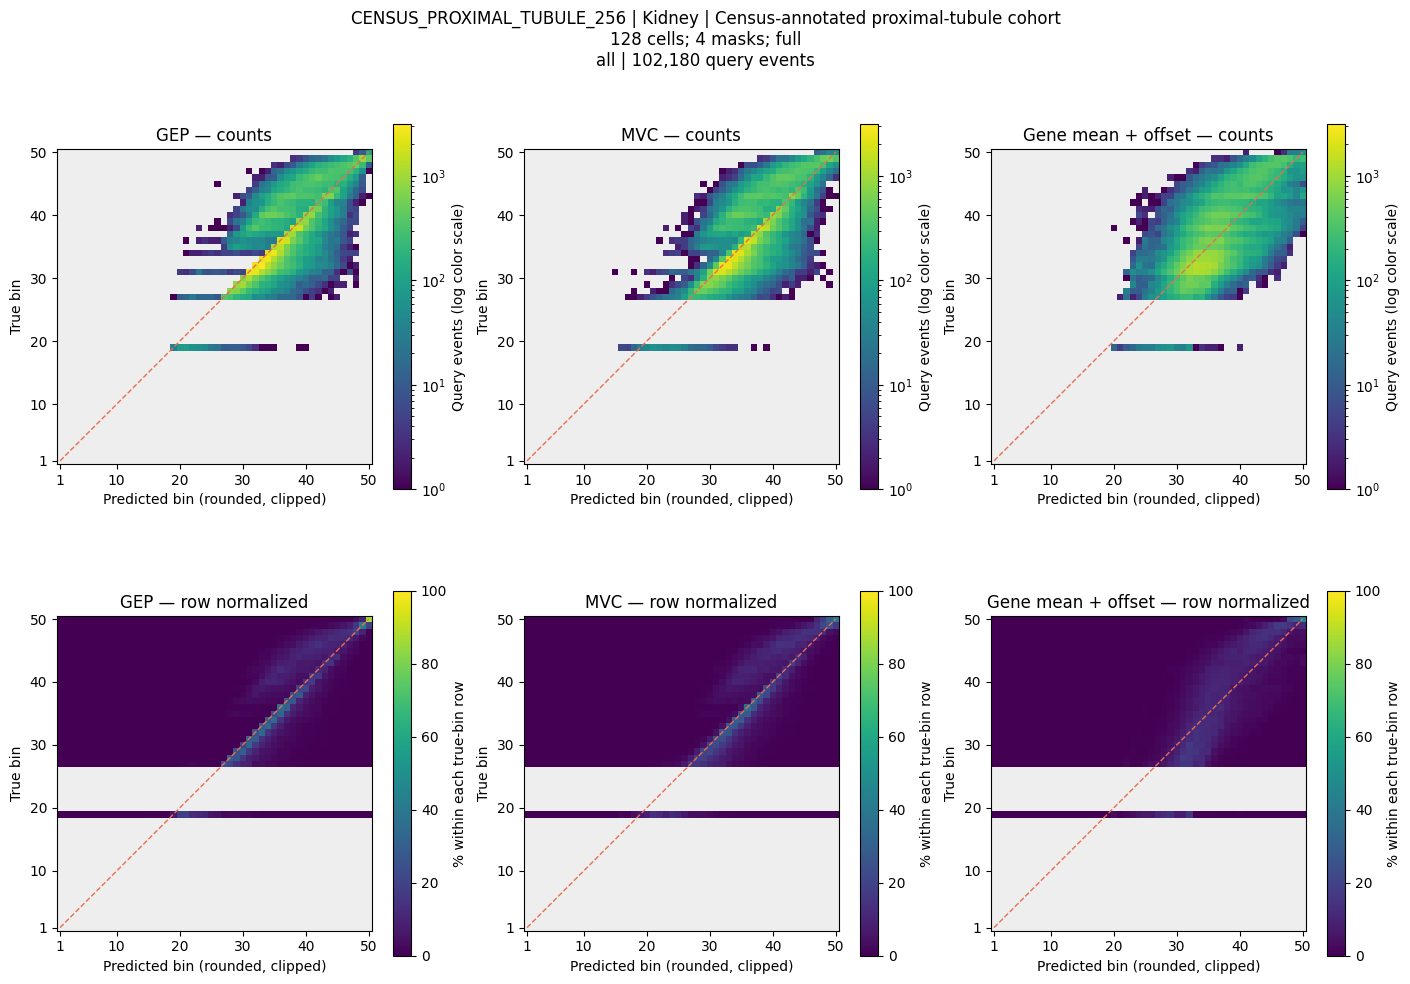

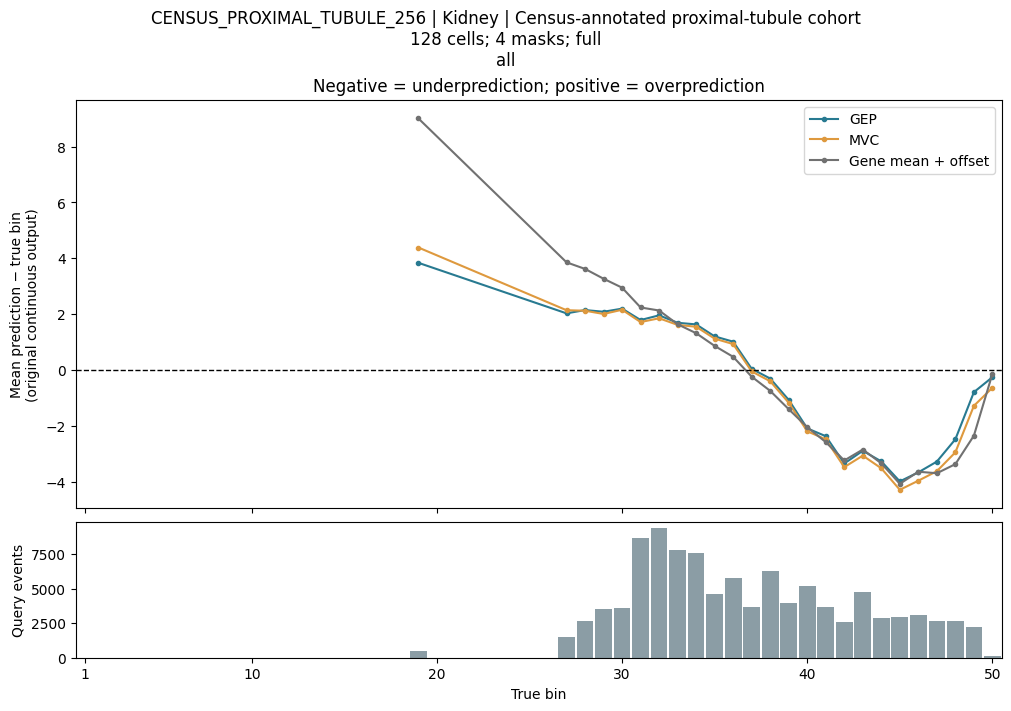

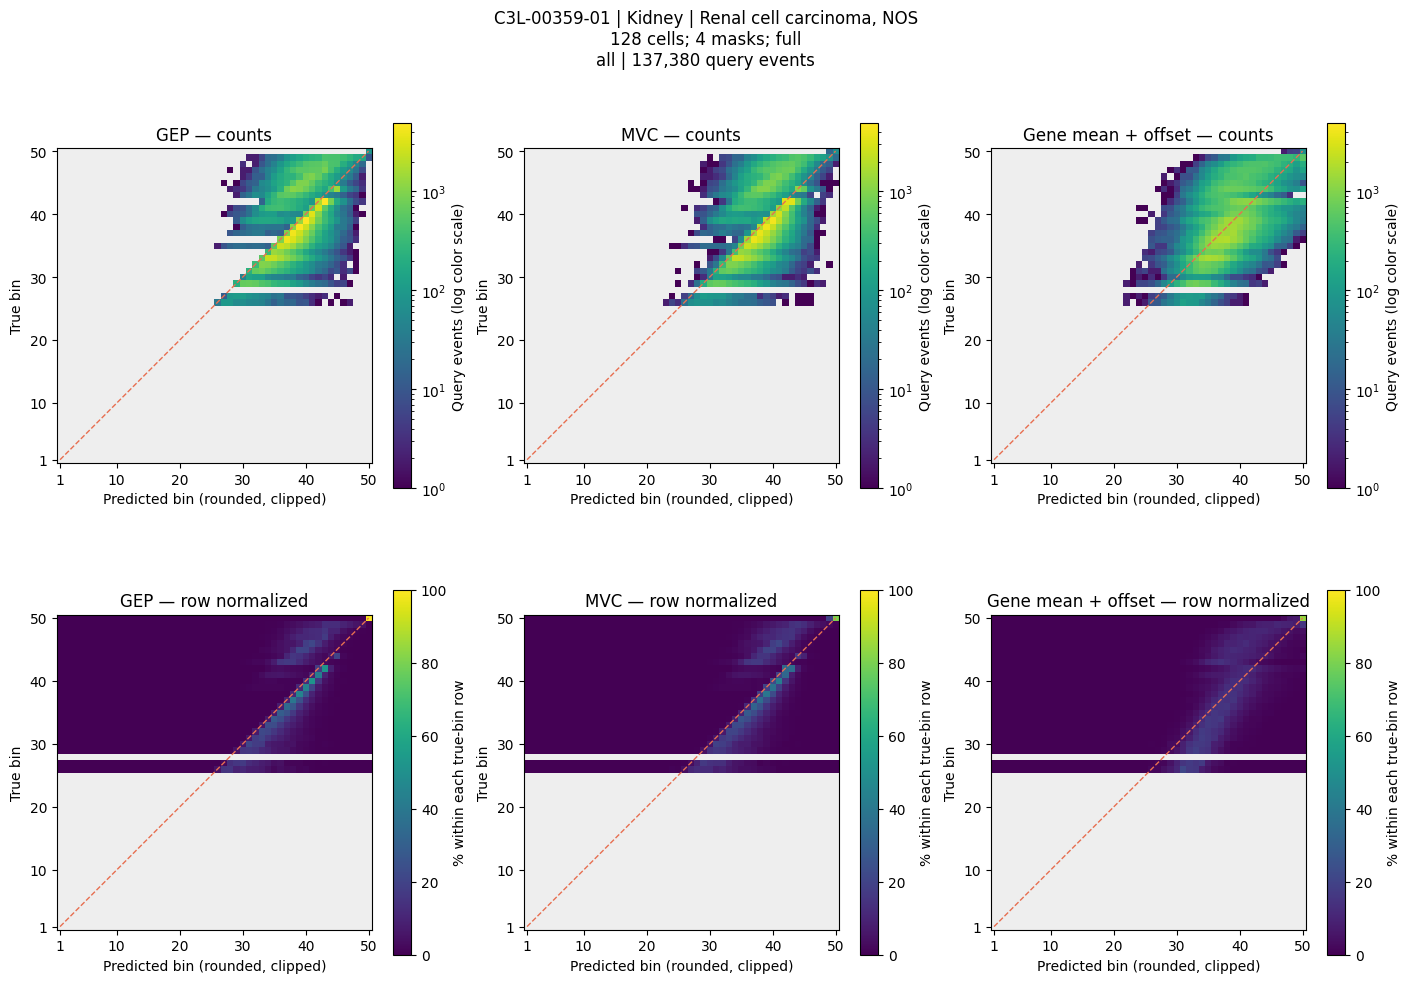

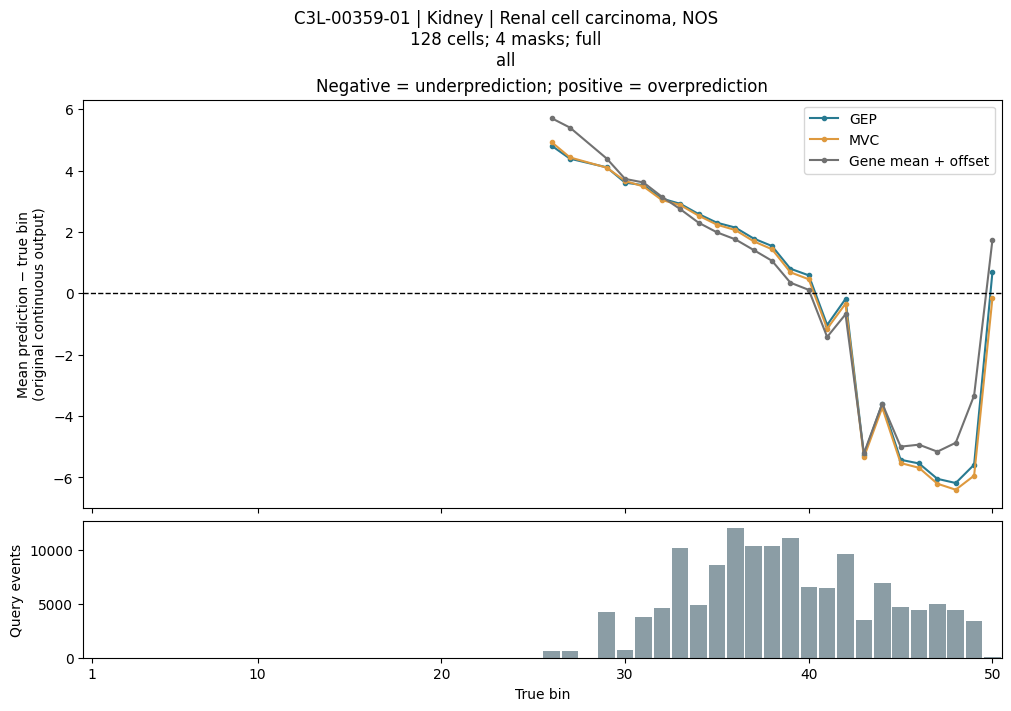

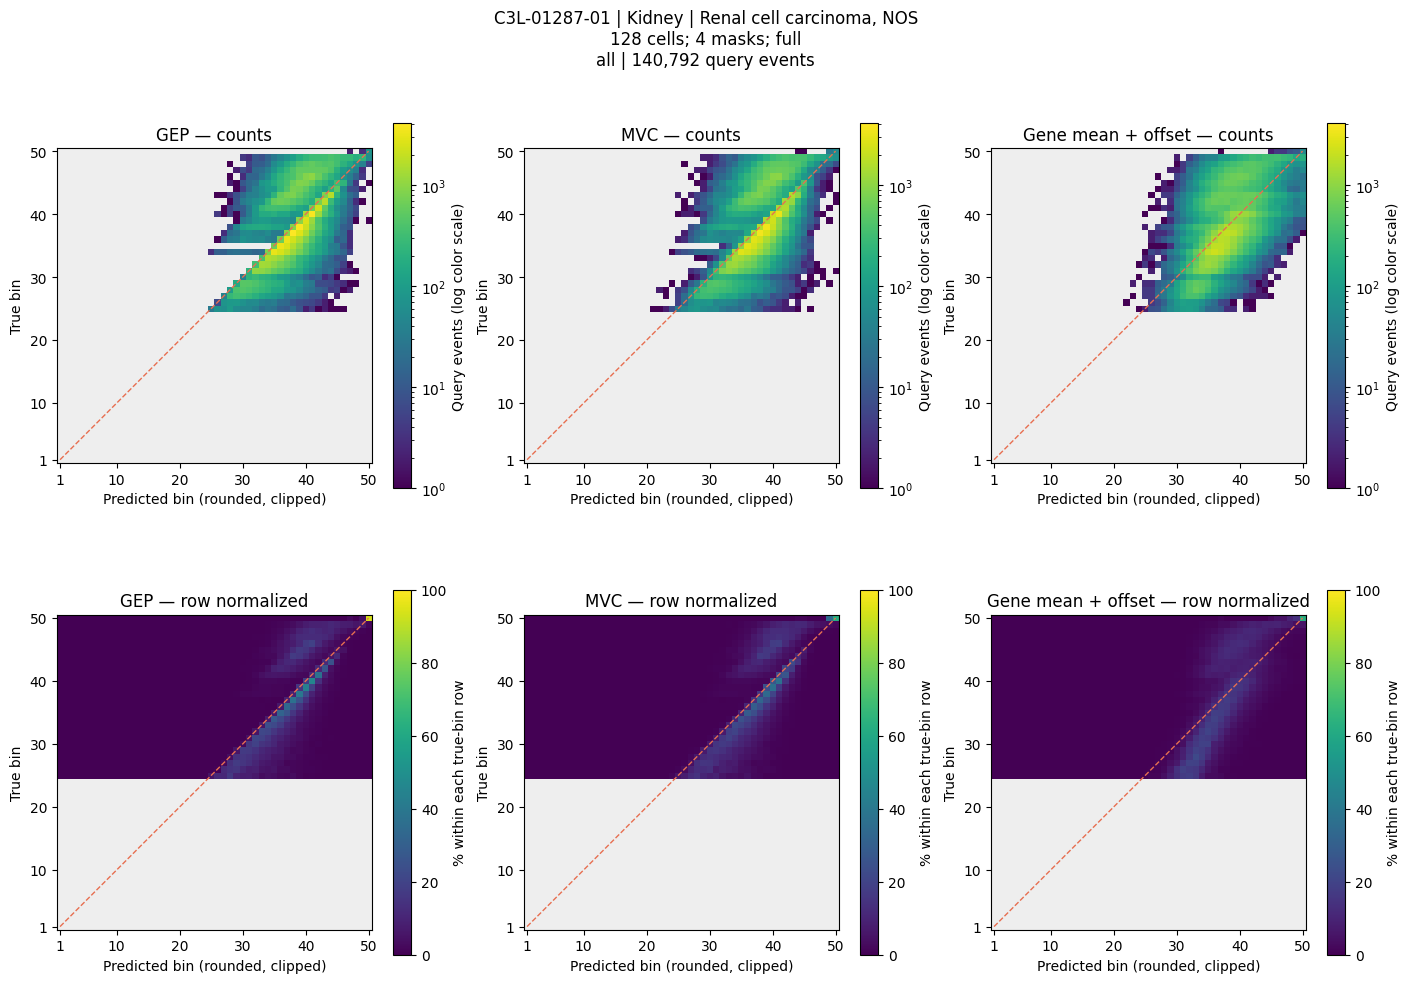

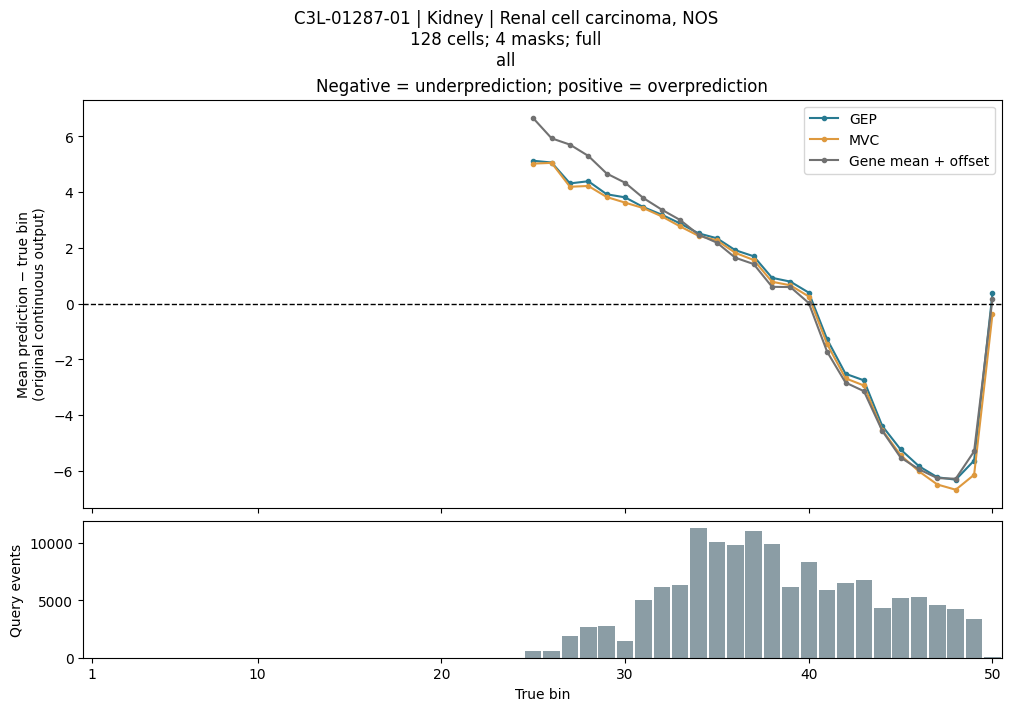

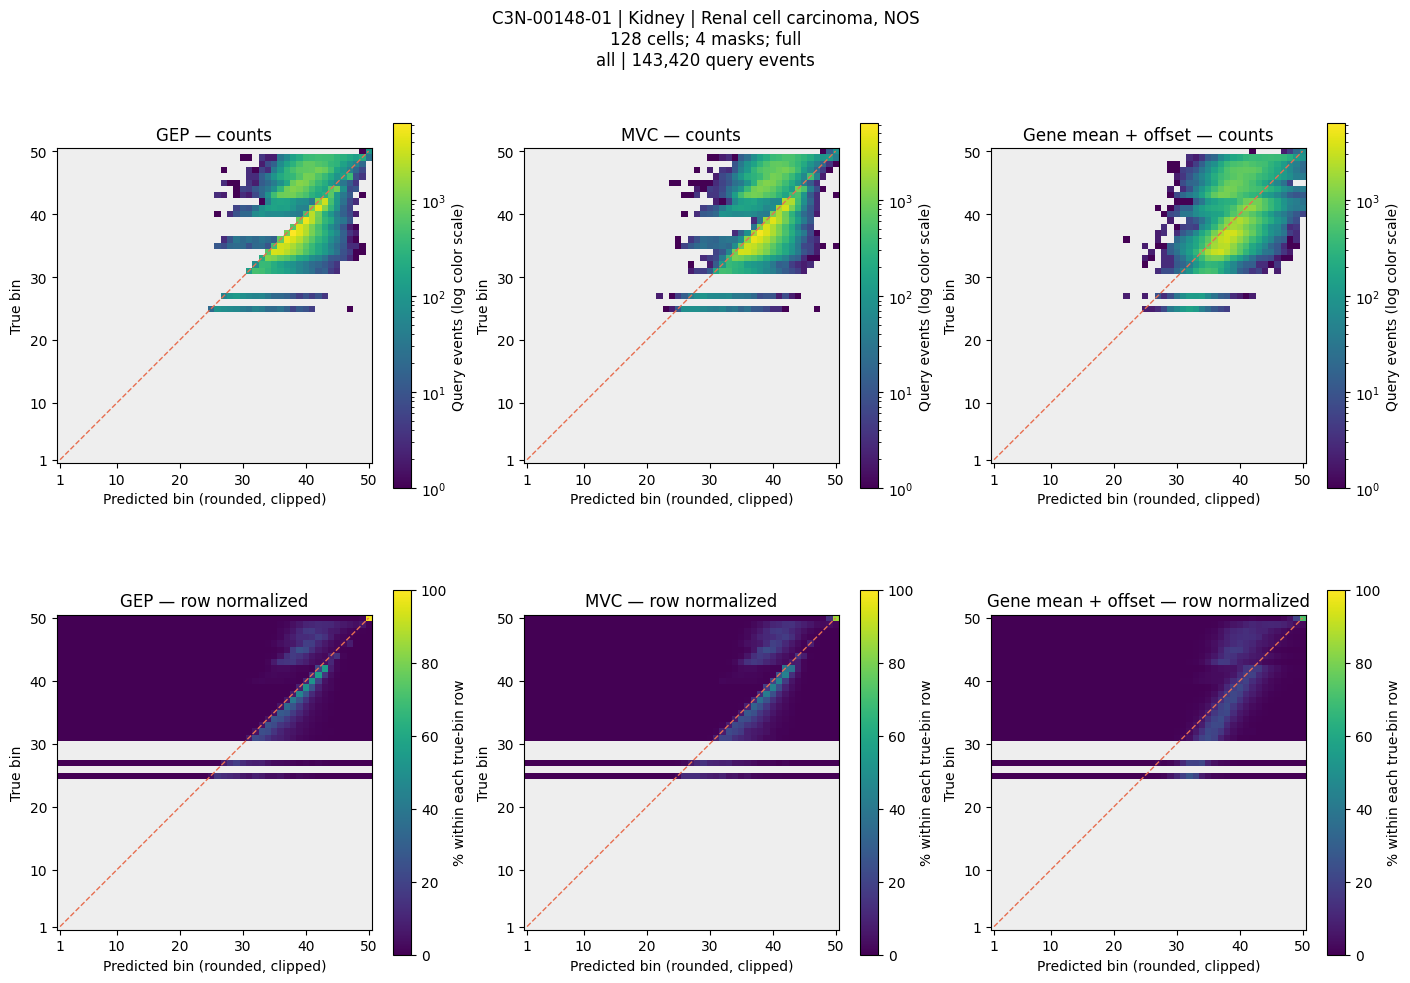

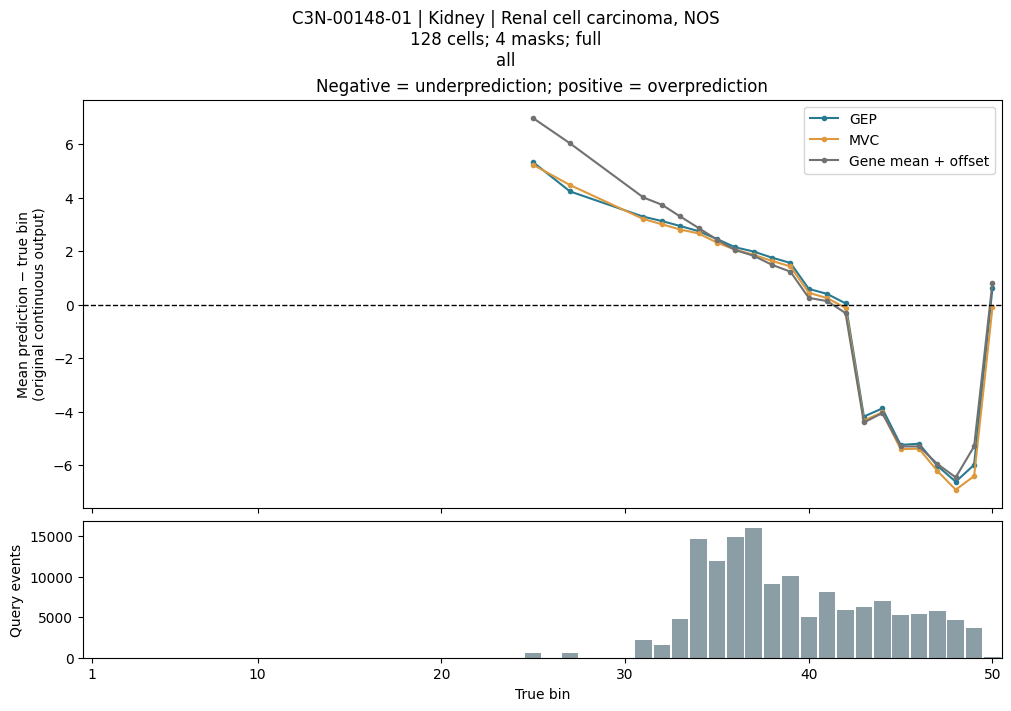

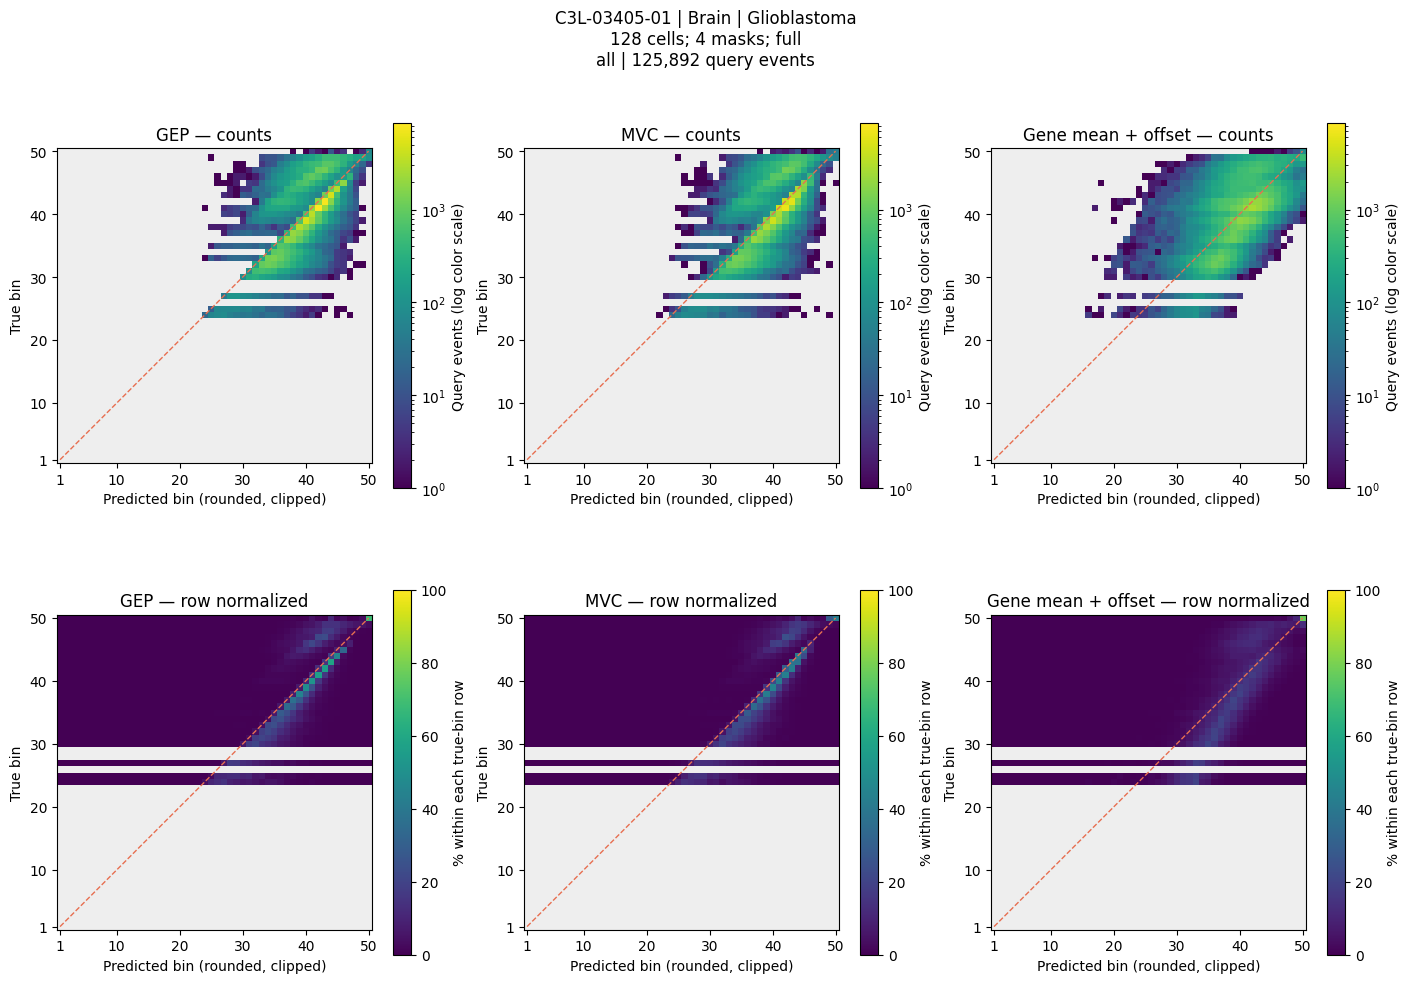

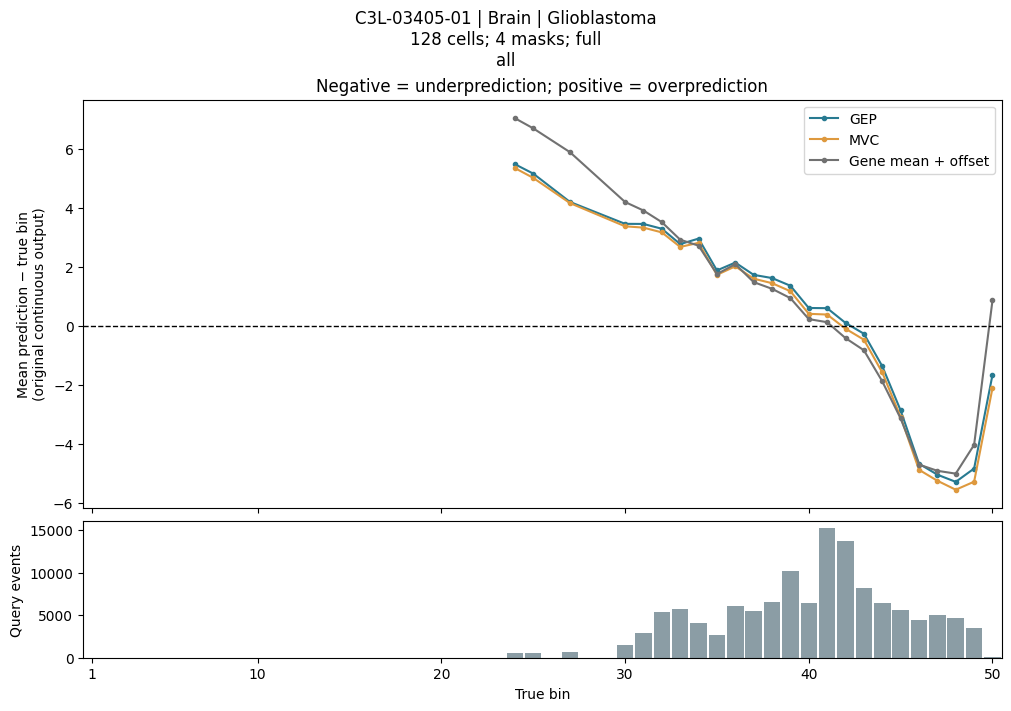

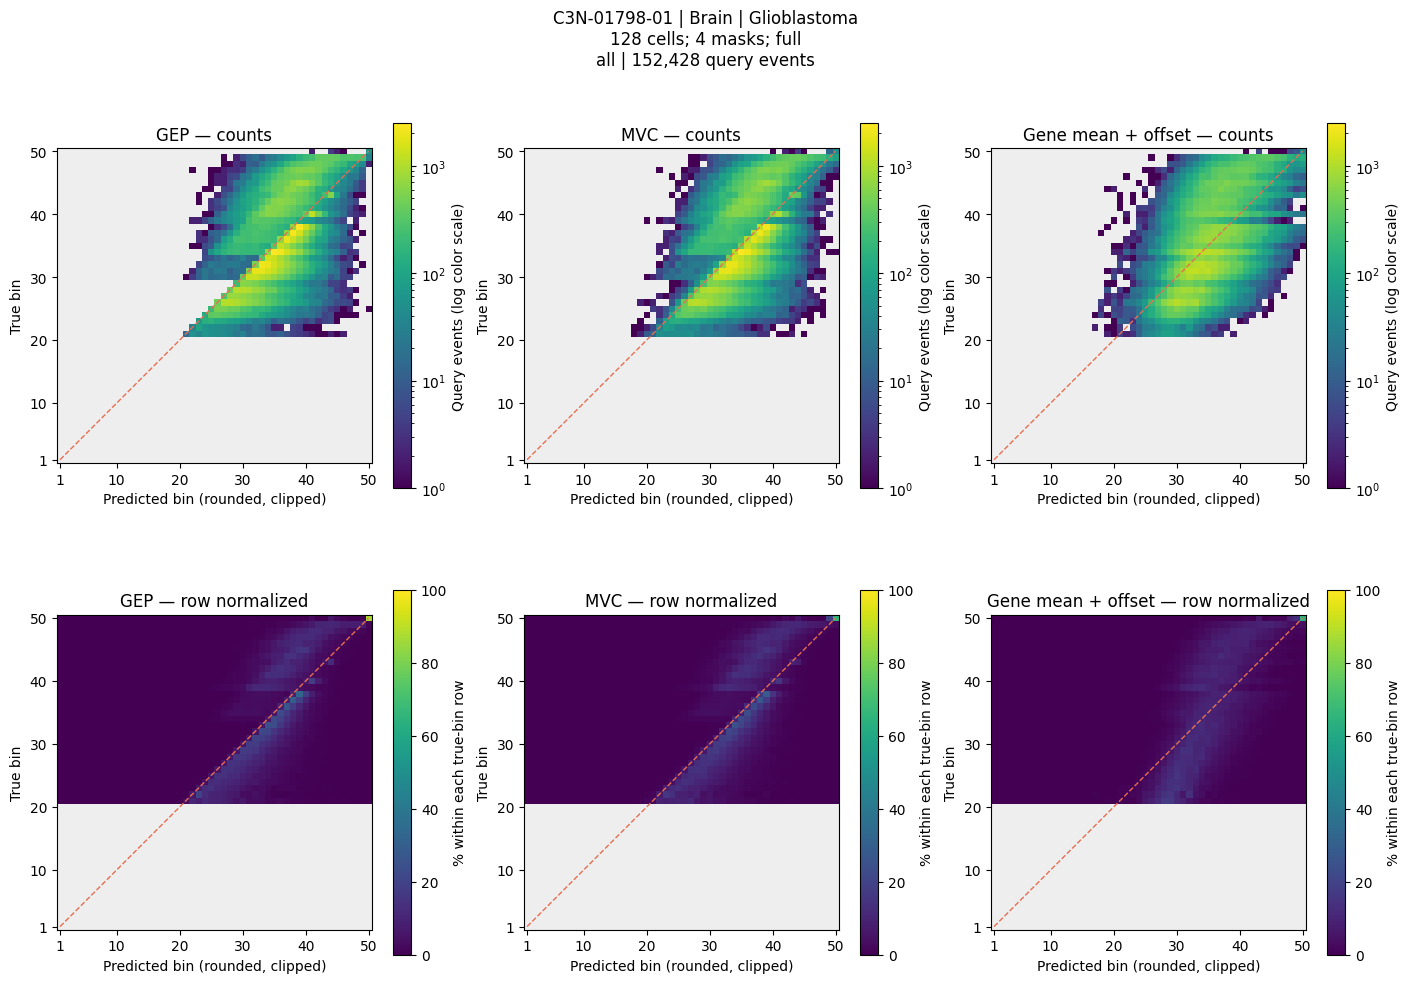

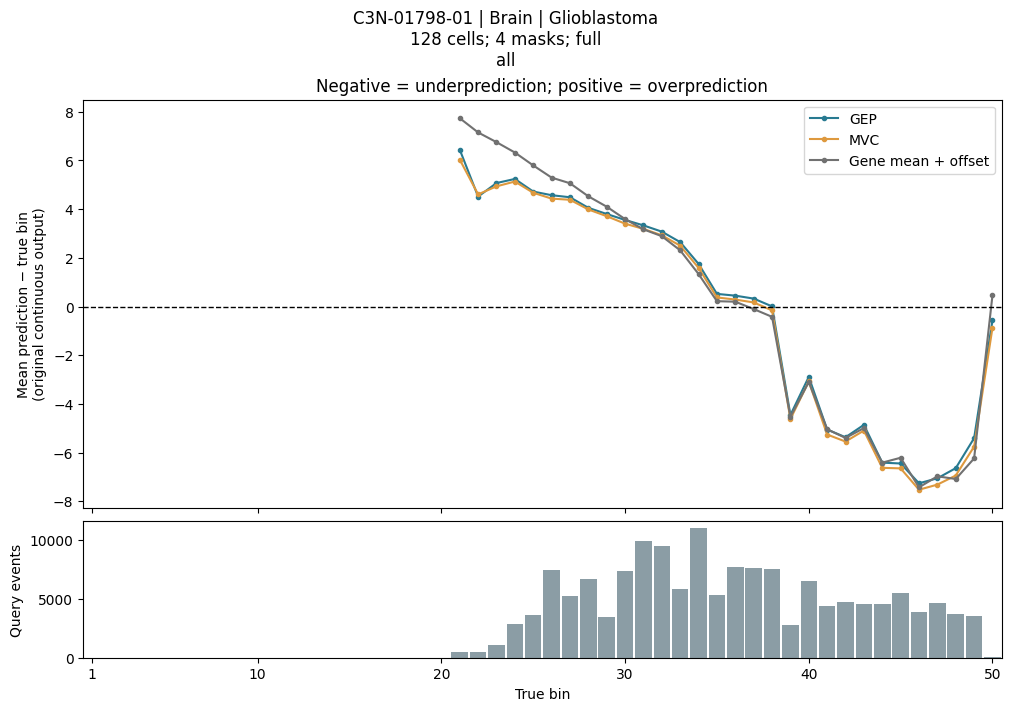

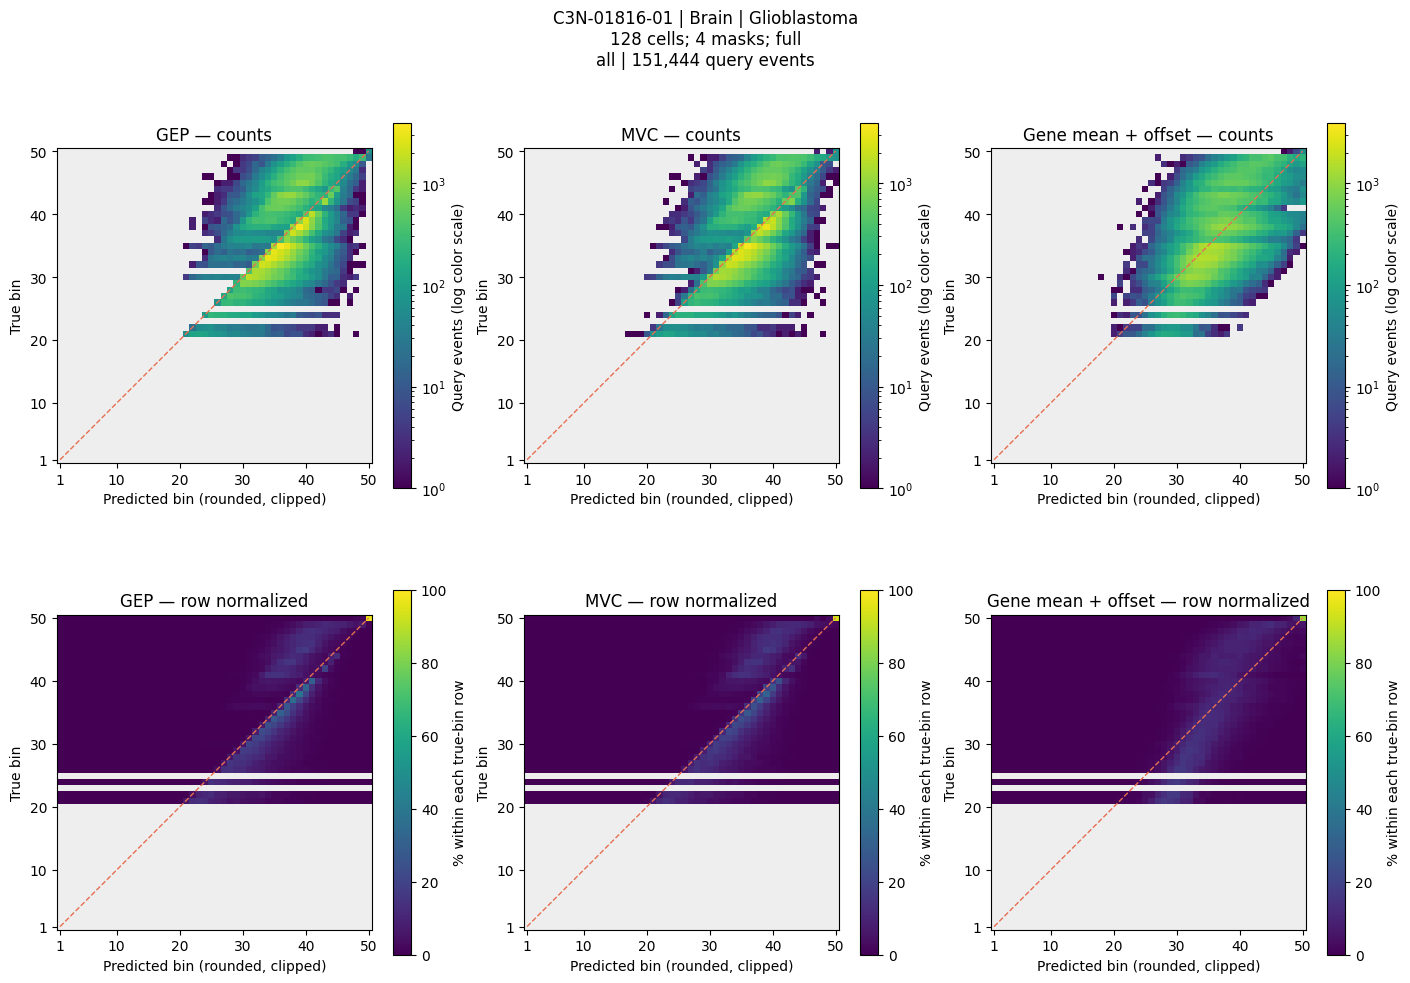

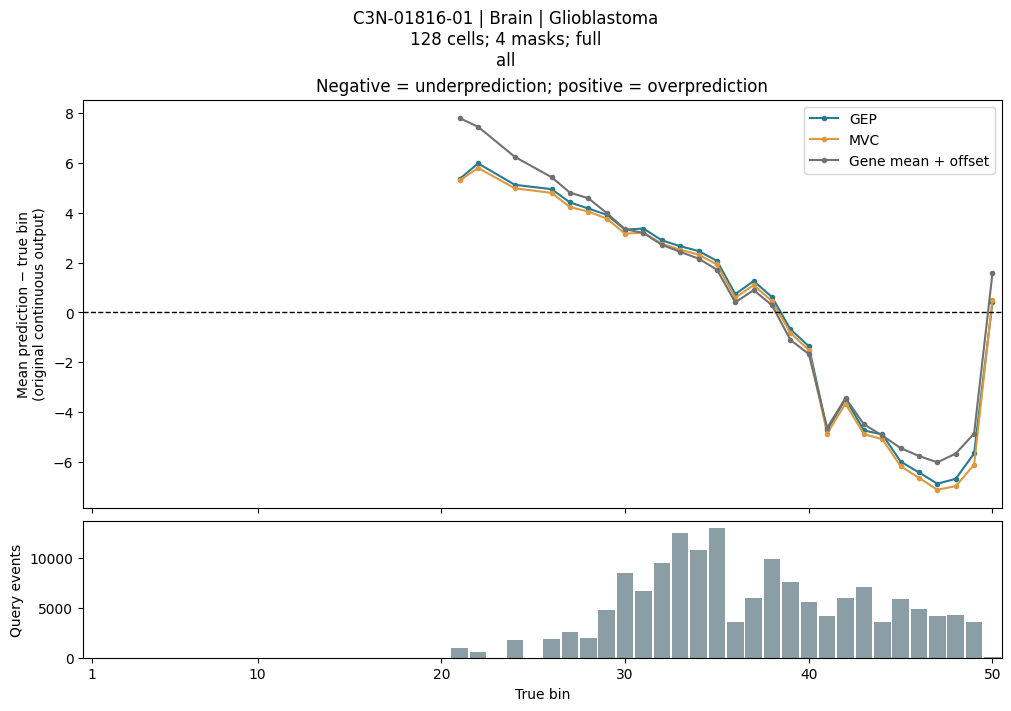

Saved all figures and tables to: /home/akash1/scgpt-cna/expression_heatmaps/20261112T145609922822Z
Grey true-bin rows mean no observations, not zero error. Query counts are not independent patients.


In [5]:
# 4 — Heat maps and continuous-error curves; all figures are saved as PNG and PDF.
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("#eeeeee")
ticks = [1,10,20,30,40,50]

def save_figure(fig, path, show):
    fig.savefig(path.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)

for dataset_id, analysis in analyses.items():
    for group, (slug, result) in analysis["groups"].items():
        show = group in DISPLAY_GROUPS
        max_count = max(m.max() for m in result["counts"].values())
        fig, axes = plt.subplots(2, len(METHODS), figsize=(14,10), constrained_layout=True, squeeze=False)
        for j, method in enumerate(METHODS):
            cm, pct = result["counts"][method], result["percent"][method]
            for i, (values, norm, scale_label) in enumerate([
                (np.ma.masked_equal(cm, 0), LogNorm(vmin=1, vmax=max(2,max_count)), "Query events (log color scale)"),
                (np.ma.masked_invalid(pct), plt.Normalize(0,100), "% within each true-bin row")]):
                ax = axes[i,j]
                im = ax.imshow(values, origin="lower", extent=[.5,50.5,.5,50.5],
                               interpolation="nearest", cmap=cmap, norm=norm, aspect="equal")
                ax.plot([1,50],[1,50], "--", color="#e76f51", lw=1)
                ax.set(xticks=ticks, yticks=ticks, xlabel="Predicted bin (rounded, clipped)", ylabel="True bin",
                       title=LABELS[method] + (" — counts" if i == 0 else " — row normalized"))
                fig.colorbar(im, ax=ax, shrink=.8, label=scale_label)
        fig.suptitle(analysis["title"] + f"\n{group} | {result['n_queries']:,} query events", fontsize=12)
        save_figure(fig, analysis["destination"]/f"{slug}_bin_heatmaps", show)

        fig, axes = plt.subplots(2,1, figsize=(10,7), sharex=True, constrained_layout=True,
                                 gridspec_kw={"height_ratios":[3,1]})
        colors = ["#287a91", "#de993e", "#717171"]
        for method, color in zip(METHODS, colors):
            curve = result["residuals"][method]
            axes[0].plot(curve.index, curve.mean_residual, ".-", color=color, label=LABELS[method])
        axes[0].axhline(0, color="black", linestyle="--", lw=1)
        axes[0].set(ylabel="Mean prediction − true bin\n(original continuous output)",
                    title="Negative = underprediction; positive = overprediction")
        axes[0].legend()
        axes[1].bar(BINS, result["support"], color="#8b9da5", width=.9)
        axes[1].set(xlabel="True bin", ylabel="Query events", xticks=ticks, xlim=(.5,50.5))
        fig.suptitle(analysis["title"] + f"\n{group}", fontsize=12)
        save_figure(fig, analysis["destination"]/f"{slug}_continuous_bias", show)
print("Saved all figures and tables to:", OUT)
print("Grey true-bin rows mean no observations, not zero error. Query counts are not independent patients.")
